<a href="https://colab.research.google.com/github/prantiqueroy/dhaka-air-enforcement/blob/main/notebooks/03_clean_and_merge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

RAW = "https://raw.githubusercontent.com/prantiqueroy/dhaka-air-enforcement/main/data/"
pm = pd.read_csv(RAW + "dhaka_pm25_2016_2025.csv", parse_dates=["time"])
wx = pd.read_csv(RAW + "dhaka_weather_2016_2025.csv", parse_dates=["time"])
print("PM2.5 rows:", len(pm), "| Weather rows:", len(wx))

PM2.5 rows: 72035 | Weather rows: 87672


In [20]:
raw = pd.read_csv(RAW + "dhaka_pm25_2016_2025.csv", parse_dates=["time"])
print("Top 15 values:", raw["pm25"].sort_values(ascending=False).head(15).values)
print("Hours at 500 or above:", (raw["pm25"] >= 500).sum())
print(raw[raw["pm25"] >= 500]["time"].dt.to_period("M").value_counts().sort_index())

Top 15 values: [985. 985. 985. 985. 985. 985. 985. 985. 985. 985. 985. 985. 985. 985.
 985.]
Hours at 500 or above: 152
time
2017-02     1
2018-01     1
2018-02     3
2018-03     1
2018-07    10
2018-08    18
2018-09     4
2019-01     3
2019-02    20
2019-03     2
2019-05     3
2020-01     1
2020-02     1
2021-01     5
2021-02     3
2021-03     8
2021-04     1
2021-12     1
2022-01     4
2022-03     3
2022-08     3
2022-09     1
2022-10     2
2022-12     4
2023-01     4
2023-04     1
2024-01     2
2024-02     4
2024-03     4
2024-12     7
2025-01    18
2025-02     8
2025-03     1
Freq: M, Name: count, dtype: int64


In [21]:
start = len(pm)

# Rule 1: remove impossible values (negative, or above the monitor's 1000 limit)
bad = (pm["pm25"] < 0) | (pm["pm25"] >= 985)   # 985+ are instrument error codes, not real readings#
print("Impossible values removed:", bad.sum())
pm = pm[~bad]

# Rule 2: remove "stuck" readings (same value 8+ hours in a row = likely a fault)
run_id = (pm["pm25"] != pm["pm25"].shift()).cumsum()
run_len = pm.groupby(run_id)["pm25"].transform("size")
stuck = run_len >= 8
print("Stuck readings removed:", stuck.sum())
pm = pm[~stuck]

print("Kept", len(pm), "of", start, "hours")

# Rule 3: remove isolated spikes (above 500 AND over 3x the surrounding 24-hour median)
pm = pm.sort_values("time").reset_index(drop=True)
local_median = pm["pm25"].rolling(25, center=True, min_periods=12).median()
spike = (pm["pm25"] > 500) & (pm["pm25"] > 3 * local_median)
print("Isolated spikes removed:", spike.sum())
print(pm.loc[spike, "time"].dt.to_period("M").value_counts().sort_index())
pm = pm[~spike]

Impossible values removed: 43
Stuck readings removed: 0
Kept 71992 of 72035 hours
Isolated spikes removed: 25
time
2018-02    2
2018-03    1
2019-01    1
2019-02    7
2019-03    2
2019-05    2
2021-02    1
2021-03    4
2021-04    1
2022-03    2
2023-04    1
2024-02    1
Freq: M, Name: count, dtype: int64


In [22]:
df = pm.merge(wx, on="time", how="left")
print("Merged rows:", len(df))
print("Hours missing weather:", df["temperature_2m"].isna().sum())
df.head()

Merged rows: 71967
Hours missing weather: 0


,time,pm25,sensor,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,month
0,2016-03-11 03:00:00,71.0,4680,24.3,92,0.0,6.2,190,3
1,2016-03-11 04:00:00,76.0,4680,24.0,94,0.0,6.0,197,3
2,2016-03-11 05:00:00,76.0,4680,23.8,95,0.0,6.2,216,3
3,2016-03-11 06:00:00,94.0,4680,23.8,95,0.0,6.1,225,3
4,2016-03-11 07:00:00,116.0,4680,24.3,94,0.0,8.2,229,3


In [23]:
df["date"] = df["time"].dt.date
daily = df.groupby("date").agg(pm25=("pm25", "mean"), hours=("pm25", "size"))
print("Days before 18-hour rule:", len(daily))
daily = daily[daily["hours"] >= 18]
print("Days kept:", len(daily))
daily.index = pd.to_datetime(daily.index)

Days before 18-hour rule: 3202
Days kept: 2893


In [24]:
# Sarwar et al. (2023) found 144–188 days per year above Bangladesh's daily standard (65)
over = daily[daily["pm25"] > 65].groupby(daily.index[daily["pm25"] > 65].year).size()
days_with_data = daily.groupby(daily.index.year).size()
print(pd.DataFrame({"days_over_65": over, "days_with_data": days_with_data}))

      days_over_65  days_with_data
date                              
2016            93             284
2017           103             279
2018            80             256
2019           171             337
2020           147             329
2021           172             316
2022           180             339
2023           177             305
2024           204             365
2025            82              83


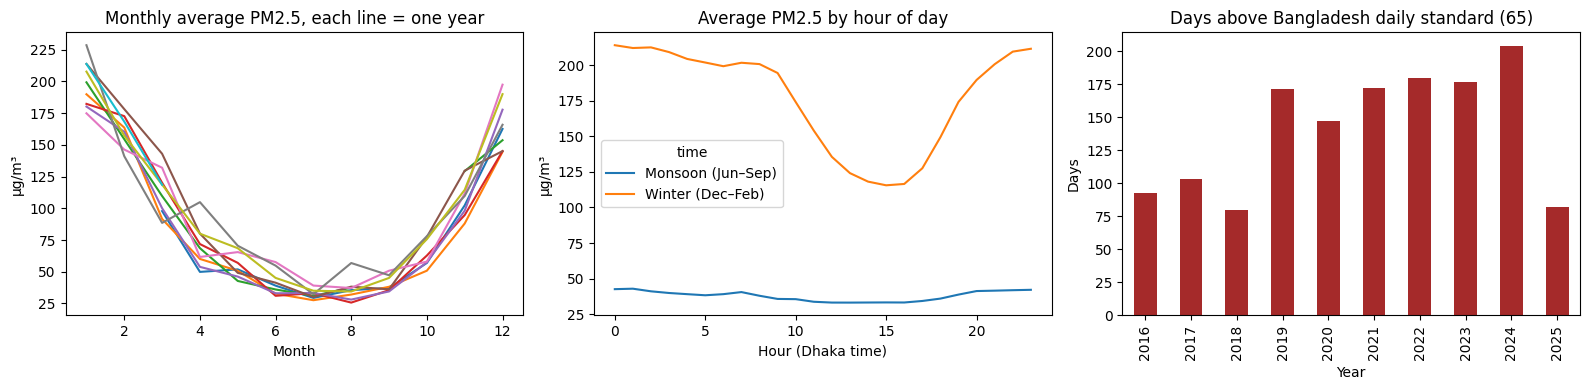

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# A. Monthly average, one line per year
m = df.groupby([df["time"].dt.year, df["time"].dt.month])["pm25"].mean().unstack(0)
m.plot(ax=ax[0], legend=False)
ax[0].set_title("Monthly average PM2.5, each line = one year")
ax[0].set_xlabel("Month"); ax[0].set_ylabel("µg/m³")

# B. Average by hour of day, winter vs monsoon
season = df["time"].dt.month.map(lambda x: "Winter (Dec–Feb)" if x in [12,1,2]
                                 else ("Monsoon (Jun–Sep)" if x in [6,7,8,9] else None))
df.groupby([season, df["time"].dt.hour])["pm25"].mean().unstack(0).plot(ax=ax[1])
ax[1].set_title("Average PM2.5 by hour of day")
ax[1].set_xlabel("Hour (Dhaka time)"); ax[1].set_ylabel("µg/m³")

# C. Days above the daily standard each year
over.plot(kind="bar", ax=ax[2], color="brown")
ax[2].set_title("Days above Bangladesh daily standard (65)")
ax[2].set_xlabel("Year"); ax[2].set_ylabel("Days")

plt.tight_layout(); plt.show()

In [26]:
df.drop(columns=["date"]).to_csv("dhaka_hourly_clean.csv", index=False)
daily.to_csv("dhaka_daily_clean.csv")
print("Saved.")

Saved.


In [27]:
# How many usable days does each month have? (2016–2018)
cov = daily.groupby([daily.index.year, daily.index.month]).size().unstack(0)
print(cov[[2016, 2017, 2018]].fillna(0).astype(int))

date  2016  2017  2018
date                  
1        0    29     9
2        0    26     5
3       20    29     8
4       29    28    18
5       30    29    22
6       29    28    28
7       30    20    29
8       30    19    26
9       29    25    28
10      30    29    27
11      28    14    28
12      29     3    28
